In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, SplineTransformer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import root_mean_squared_error

import os
os.chdir('/Users/lior/DS6021/DS6021_F26/data')

In [3]:
bike = pd.read_csv("bike-sharing-daily.csv")
Xb, yb = bike[["temp"]], bike["cnt"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=42)
bike_models = {
    "A: Linear": make_pipeline(LinearRegression()),
    "B: Poly deg 9": make_pipeline(StandardScaler(), PolynomialFeatures(9, include_bias=False), LinearRegression()),
    "C: Spline 7 knots": make_pipeline(SplineTransformer(degree=3, n_knots=7, knots="quantile"), LinearRegression()),
}
for m in bike_models.values(): m.fit(Xb_tr, yb_tr)

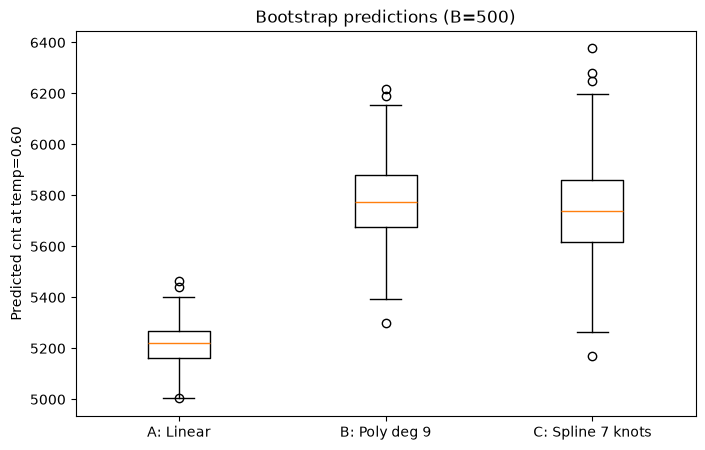

      A: Linear  B: Poly deg 9  C: Spline 7 knots
mean     5217.1         5775.3             5743.7
std        74.5          149.4              179.6
min      5003.4         5299.1             5170.9
max      5466.1         6218.7             6376.4


In [ ]:
rng = np.random.default_rng(42)
B = 500 #used claude to clean
x0 = pd.DataFrame({"temp": [0.60]})

n = len(Xb_tr)
preds = {name: [] for name in bike_models}
for b in range(B):
    idx = rng.integers(0, n, n)
    Xs, ys = Xb_tr.iloc[idx], yb_tr.iloc[idx]
    for name, m in bike_models.items():
        preds[name].append(m.fit(Xs, ys).predict(x0)[0])
preds = pd.DataFrame(preds)
plt.figure(figsize=(8, 5)); 
plt.boxplot([preds[c] for c in preds], tick_labels=list(preds.columns));
plt.ylabel("Predicted cnt at temp=0.60"); 
plt.title("Bootstrap predictions (B=500)");
plt.show()
print(preds.agg(["mean", "std", "min", "max"]).round(1))

1a

model a seems like its the most stable since it has the tightest box and an std of 74.5 . model c is the most variable with an std of 179.6.

1b. 

The more flexible a model is, the more sensitive it is to training samples. linear has few params so resampling doesnt change it, but the other two have more parameters so each sample is chased and the predictions move around every time. So the more flexible a model is, the more variance there is but theres less bias.

1c.

the model has a high variance and most of the noise is coming from the training sample but it isnt actually its true pattern. If you gave it a different sample, it would give you a different pattern, so it would not be able to generalize well when it comes to new data, whether the training error is high or low.


2a

Model A has a high bias and a low variance (underfited) but it is stable. The CV and test errors are the highest. Model B has low bias, high variance, and it follows the curve so it has a lower CV error, but the predictions vary. test error is higher than training error. For model C,its the same thing with B except it has the lowest CV value but the largest bootstrap spread. So going from A to any of the other models leads to more variance but less bias and since the bias drop is larger than the rise in variance, models b and c still have lower test and cv errors.

2b

we shouldnt do that because the smallest training rmse only really measures the data its already seen and how well it fits the model. Having a more flexible model might generalize it worse because it lowers training error by overfitting. A better way to do it would be to use test error or cross validating which estimates the performance of the new data and also keeps the bias and variance in check.